<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/07_mask_rcnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — Mask R-CNN

## 1. Initialisation et chargement des données

**Objectif :** détecter et segmenter individuellement les obstacles présents sur la route.

Nous utilisons Mask R-CNN avec un backbone ResNet50-FPN préentraîné.

Le dataset contient 60 images, dont 46 disposent d'annotations d'instances représentant 201 obstacles.

Nous conservons les mêmes splits que pour les modèles précédents afin d'éviter toute fuite de données.

In [1]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import torch
import torchvision

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/deep learning P")
SPLIT_PATH = PROJECT_DIR / "split_manifest.csv"

df = pd.read_csv(SPLIT_PATH)

# Conserver uniquement les images annotées pour les instances
instance_df = df[df["instance_mask"].notna()].copy()

train_df = instance_df[
    instance_df["split"] == "train"
].reset_index(drop=True)

val_df = instance_df[
    instance_df["split"] == "validation"
].reset_index(drop=True)

test_df = instance_df[
    instance_df["split"] == "test"
].reset_index(drop=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))
print("Device :", device)
print("PyTorch :", torch.__version__)
print("Torchvision :", torchvision.__version__)

Mounted at /content/drive
Train : 33
Validation : 5
Test : 8
Device : cuda
PyTorch : 2.14.1+cu130
Torchvision : 0.29.1+cu130


## 2. Préparation des données pour Mask R-CNN

Nous transformons les annotations d'instances en un format compatible avec Torchvision Mask R-CNN.

Chaque image possède :
- Des bounding boxes au format `[xmin, ymin, xmax, ymax]`.
- Un label `1` pour chaque obstacle.
- Un masque binaire individuel pour chaque obstacle.

Les images et les masques sont redimensionnés à 256 × 256 en conservant leurs proportions. Les augmentations sont appliquées uniquement aux images d'entraînement.

In [2]:
import numpy as np
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader

IMG_SIZE = (256, 256)


class RoadAnomalyInstanceDataset(Dataset):

    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        # Image RGB
        image = Image.open(row["image"]).convert("RGB")
        image = ImageOps.pad(
            image, IMG_SIZE,
            method=Image.Resampling.BILINEAR,
            color=(0, 0, 0)
        )

        image = np.asarray(image, dtype=np.float32) / 255.0

        # Masque d'instances : conserver les IDs
        instance_mask = Image.open(row["instance_mask"])
        instance_mask = ImageOps.pad(
            instance_mask, IMG_SIZE,
            method=Image.Resampling.NEAREST,
            color=0
        )
        instance_mask = np.asarray(instance_mask)

        # Augmentation horizontale
        if self.augment:
            if self.rng.random() < 0.5:
                image = np.flip(image, axis=1).copy()
                instance_mask = np.flip(instance_mask, axis=1).copy()

            image = np.clip(
                image * self.rng.uniform(0.8, 1.2),
                0, 1
            )

            mean = image.mean(axis=(0, 1), keepdims=True)
            image = np.clip(
                (image - mean) * self.rng.uniform(0.8, 1.2) + mean,
                0, 1
            )

        # Extraire un masque par objet
        object_ids = np.unique(instance_mask)
        object_ids = object_ids[object_ids != 0]

        masks = []
        boxes = []
        areas = []

        for obj_id in object_ids:
            binary_mask = (instance_mask == obj_id).astype(np.uint8)

            ys, xs = np.where(binary_mask)

            if len(xs) == 0:
                continue

            xmin, xmax = xs.min(), xs.max()
            ymin, ymax = ys.min(), ys.max()

            # Coordonnées valides pour Mask R-CNN
            xmax = min(xmax + 1, IMG_SIZE[0])
            ymax = min(ymax + 1, IMG_SIZE[1])

            masks.append(binary_mask)
            boxes.append([xmin, ymin, xmax, ymax])
            areas.append((xmax - xmin) * (ymax - ymin))

        if masks:
            masks = torch.as_tensor(
                np.stack(masks), dtype=torch.uint8
            )
            boxes = torch.as_tensor(
                boxes, dtype=torch.float32
            )
            areas = torch.as_tensor(
                areas, dtype=torch.float32
            )
        else:
            masks = torch.zeros(
                (0, 256, 256), dtype=torch.uint8
            )
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            areas = torch.zeros((0,), dtype=torch.float32)

        labels = torch.ones(
            len(boxes), dtype=torch.int64
        )

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": torch.tensor(idx, dtype=torch.int64),
            "area": areas,
            "iscrowd": torch.zeros(
                len(boxes), dtype=torch.int64
            )
        }

        return image, target


# Mask R-CNN accepte des images avec des nombres
# différents d'objets : collate_fn personnalisé.
def collate_fn(batch):
    return tuple(zip(*batch))


train_loader = DataLoader(
    RoadAnomalyInstanceDataset(train_df, augment=True),
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

val_loader = DataLoader(
    RoadAnomalyInstanceDataset(val_df),
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

test_loader = DataLoader(
    RoadAnomalyInstanceDataset(test_df),
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

# Vérification rapide
images, targets = next(iter(train_loader))

print("Images dans le batch :", len(images))
print("Taille image :", images[0].shape)
print("Boxes :", targets[0]["boxes"].shape)
print("Labels :", targets[0]["labels"].shape)
print("Masks :", targets[0]["masks"].shape)
print("Device :", device)

Images dans le batch : 2
Taille image : torch.Size([3, 256, 256])
Boxes : torch.Size([6, 4])
Labels : torch.Size([6])
Masks : torch.Size([6, 256, 256])
Device : cuda


## 3. Construction du modèle Mask R-CNN

Nous utilisons Mask R-CNN avec un backbone ResNet50-FPN préentraîné sur COCO.

Le modèle est adapté à deux classes : arrière-plan et anomalie.

Nous remplaçons les têtes de classification et de segmentation pour apprendre à détecter les obstacles routiers individuellement.

Le modèle prédit des bounding boxes, des classes et des masques d'instances.

In [3]:
import torch
import torchvision
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

NUM_CLASSES = 2

# Charger Mask R-CNN préentraîné sur COCO
model = maskrcnn_resnet50_fpn(
    weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT,
    min_size=256,
    max_size=256
)

# Remplacer la tête de classification
in_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    NUM_CLASSES
)

# Remplacer la tête de segmentation
in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
hidden_layer = 256

model.roi_heads.mask_predictor = MaskRCNNPredictor(
    in_features_mask,
    hidden_layer,
    NUM_CLASSES
)

# Envoyer le modèle sur le GPU
model = model.to(device)

print("Modèle :", type(model).__name__)
print("Backbone : ResNet50-FPN")
print("Nombre de classes :", NUM_CLASSES)
print(
    "Paramètres entraînables :",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)
print("Device :", device)

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 132MB/s]


Modèle : MaskRCNN
Backbone : ResNet50-FPN
Nombre de classes : 2
Paramètres entraînables : 43699995
Device : cuda


## 4. Configuration de l'optimiseur

Mask R-CNN utilise plusieurs fonctions de perte internes :

- **Classification Loss :** classification des objets.
- **Box Regression Loss :** localisation des bounding boxes.
- **Mask Loss :** segmentation de chaque obstacle.
- **RPN Losses :** génération et évaluation des propositions d'objets.

Nous utilisons AdamW avec un learning rate de 0.0001 et une régularisation weight decay de 0.0001.

La perte totale correspond à la somme des pertes calculées par Mask R-CNN.

In [4]:
import torch

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("Optimizer :", type(optimizer).__name__)
print("Learning rate :", optimizer.param_groups[0]["lr"])
print("Weight decay :", optimizer.param_groups[0]["weight_decay"])
print("Nombre de paramètres entraînables :",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Optimizer : AdamW
Learning rate : 0.0001
Weight decay : 0.0001
Nombre de paramètres entraînables : 43699995


## 5. Entraînement et validation de Mask R-CNN

Nous effectuons le fine-tuning du modèle préentraîné sur COCO.

- **Train :** 33 images annotées.
- **Validation :** 5 images annotées.
- **Batch size :** 2.
- **Époques :** maximum 20.
- **Early Stopping :** patience de 5 époques.
- **Checkpoint :** sauvegarde du modèle ayant la meilleure perte de validation.

La perte totale combine les pertes de classification, de localisation, de segmentation et du RPN.

Les images de test restent exclues de l'entraînement et de la sélection du modèle.

In [5]:
from pathlib import Path
import torch
import gc

EPOCHS = 20
PATIENCE = 5

best_val_loss = float("inf")
patience_counter = 0

train_losses = []
val_losses = []

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "mask_rcnn_best.pth"

for epoch in range(EPOCHS):

    # Entraînement
    model.train()
    total_train_loss = 0.0

    for images, targets in train_loader:

        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in target.items()}
            for target in targets
        ]

        optimizer.zero_grad()

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(images)

    train_loss = total_train_loss / len(train_loader.dataset)

    # Validation
    # Torchvision Mask R-CNN renvoie les pertes en mode train.
    # no_grad() empêche le calcul des gradients.
    model.train()
    total_val_loss = 0.0

    with torch.no_grad():
        for images, targets in val_loader:

            images = [img.to(device) for img in images]

            targets = [
                {k: v.to(device) for k, v in target.items()}
                for target in targets
            ]

            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())

            total_val_loss += loss.item() * len(images)

    val_loss = total_val_loss / len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # Sauvegarde du meilleur modèle
    if val_loss < best_val_loss - 1e-4:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(model.state_dict(), MODEL_PATH)

    else:
        patience_counter += 1

    # Early Stopping
    if patience_counter >= PATIENCE:
        print("\nEarly Stopping activated.")
        break

model.eval()

print("\nTraining completed!")
print("Best Validation Loss :", round(best_val_loss, 4))
print(
    "Best Epoch :",
    val_losses.index(min(val_losses)) + 1
)
print("Model saved at :", MODEL_PATH)

Epoch 01/20 | Train Loss: 1.6119 | Val Loss: 1.3032
Epoch 02/20 | Train Loss: 1.1062 | Val Loss: 1.0639
Epoch 03/20 | Train Loss: 0.9237 | Val Loss: 0.8849
Epoch 04/20 | Train Loss: 0.8115 | Val Loss: 0.8545
Epoch 05/20 | Train Loss: 0.7581 | Val Loss: 0.9799
Epoch 06/20 | Train Loss: 0.7238 | Val Loss: 0.8153
Epoch 07/20 | Train Loss: 0.7408 | Val Loss: 0.8194
Epoch 08/20 | Train Loss: 0.6846 | Val Loss: 0.9005
Epoch 09/20 | Train Loss: 0.6653 | Val Loss: 0.8171
Epoch 10/20 | Train Loss: 0.6201 | Val Loss: 0.8149
Epoch 11/20 | Train Loss: 0.6363 | Val Loss: 1.0072
Epoch 12/20 | Train Loss: 0.6267 | Val Loss: 0.8644
Epoch 13/20 | Train Loss: 0.5773 | Val Loss: 0.8862
Epoch 14/20 | Train Loss: 0.5803 | Val Loss: 1.0486
Epoch 15/20 | Train Loss: 0.5517 | Val Loss: 1.0141

Early Stopping activated.

Training completed!
Best Validation Loss : 0.8149
Best Epoch : 10
Model saved at : /content/drive/MyDrive/deep learning P/models/mask_rcnn_best.pth


## 6. Analyse des courbes d'apprentissage

Nous visualisons les pertes d'entraînement et de validation de Mask R-CNN.

L'objectif est d'observer la convergence du modèle et de comprendre le déclenchement de l'Early Stopping.

Le meilleur checkpoint est obtenu à l'époque 10, avec une Validation Loss de 0.8149.

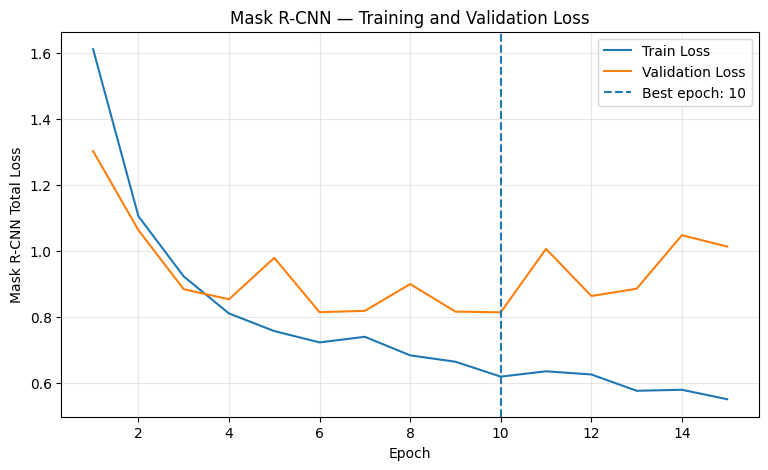

Best epoch : 10
Best Validation Loss : 0.8149


In [6]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(train_losses) + 1)
best_epoch = int(np.argmin(val_losses)) + 1

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mask R-CNN Total Loss")
plt.title("Mask R-CNN — Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best epoch :", best_epoch)
print("Best Validation Loss :", round(min(val_losses), 4))

## 7. Évaluation de Mask R-CNN

Nous évaluons Mask R-CNN sur les 8 images de test.

Métriques utilisées :
- **Mask IoU :** chevauchement entre un masque prédit et un masque réel.
- **Precision :** proportion des obstacles prédits correctement.
- **Recall :** proportion des obstacles réels détectés.
- **AP@50 :** Average Precision avec un seuil Mask IoU de 0.5.

Pour Precision et Recall, nous utilisons un seuil de confiance de 0.5.

Chaque obstacle réel ne peut être associé qu'à une seule prédiction.

In [7]:
import torch
import numpy as np

# Charger le meilleur checkpoint
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

IOU_THRESHOLD = 0.5
SCORE_THRESHOLD = 0.5

all_predictions = []
total_gt = 0

# Calcul du Mask IoU
def mask_iou(mask1, mask2):
    intersection = (mask1 & mask2).sum().item()
    union = (mask1 | mask2).sum().item()
    return intersection / union if union > 0 else 0.0

# Prédictions sur les 8 images
with torch.no_grad():
    for images, targets in test_loader:
        images_gpu = [img.to(device) for img in images]
        outputs = model(images_gpu)

        for output, target in zip(outputs, targets):

            pred_masks = (
                output["masks"][:, 0].cpu() >= 0.5
            )
            scores = output["scores"].cpu().tolist()
            pred_labels = output["labels"].cpu().tolist()

            gt_masks = target["masks"].bool()
            total_gt += len(gt_masks)

            # Trier les prédictions par confiance
            order = np.argsort(scores)[::-1]
            matched_gt = set()

            for idx in order:
                if pred_labels[idx] != 1:
                    continue

                best_iou = 0.0
                best_gt = -1

                for j in range(len(gt_masks)):
                    if j in matched_gt:
                        continue

                    iou = mask_iou(
                        pred_masks[idx], gt_masks[j]
                    )

                    if iou > best_iou:
                        best_iou = iou
                        best_gt = j

                correct = (
                    best_iou >= IOU_THRESHOLD
                    and best_gt != -1
                )

                if correct:
                    matched_gt.add(best_gt)

                all_predictions.append({
                    "score": scores[idx],
                    "tp": int(correct),
                    "iou": best_iou if correct else 0.0
                })

# Precision et Recall à score >= 0.5
selected = [
    p for p in all_predictions
    if p["score"] >= SCORE_THRESHOLD
]

TP = sum(p["tp"] for p in selected)
FP = len(selected) - TP
FN = total_gt - TP

precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / total_gt if total_gt else 0.0

matched_ious = [
    p["iou"] for p in selected if p["tp"] == 1
]

mean_iou = (
    np.mean(matched_ious) if matched_ious else 0.0
)

# AP@50 : toutes les prédictions classées par score
ranked = sorted(
    all_predictions,
    key=lambda p: p["score"],
    reverse=True
)

tp_cum = np.cumsum([p["tp"] for p in ranked])
fp_cum = np.cumsum([1 - p["tp"] for p in ranked])

recalls = tp_cum / max(total_gt, 1)
precisions = tp_cum / np.maximum(tp_cum + fp_cum, 1)

# Intégration de la courbe Precision-Recall
mrec = np.concatenate(([0], recalls, [1]))
mpre = np.concatenate(([0], precisions, [0]))

for i in range(len(mpre) - 2, -1, -1):
    mpre[i] = max(mpre[i], mpre[i + 1])

indices = np.where(mrec[1:] != mrec[:-1])[0]
ap50 = np.sum(
    (mrec[indices + 1] - mrec[indices])
    * mpre[indices + 1]
)

print("Mask R-CNN — Test Results")
print(f"Mask IoU  : {mean_iou:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"AP@50     : {ap50:.4f}")
print(f"TP: {TP} | FP: {FP} | FN: {FN}")

Mask R-CNN — Test Results
Mask IoU  : 0.7378
Precision : 0.3714
Recall    : 0.5417
AP@50     : 0.5402
TP: 13 | FP: 22 | FN: 11


## 8. Visualisation des prédictions Mask R-CNN

Nous comparons les annotations réelles et les prédictions du modèle sur trois images de test.

Nous affichons les bounding boxes et les masques individuels des obstacles avec un seuil de confiance de 0.5.

Cette visualisation permet d'identifier les objets détectés, les faux positifs et les obstacles manqués.

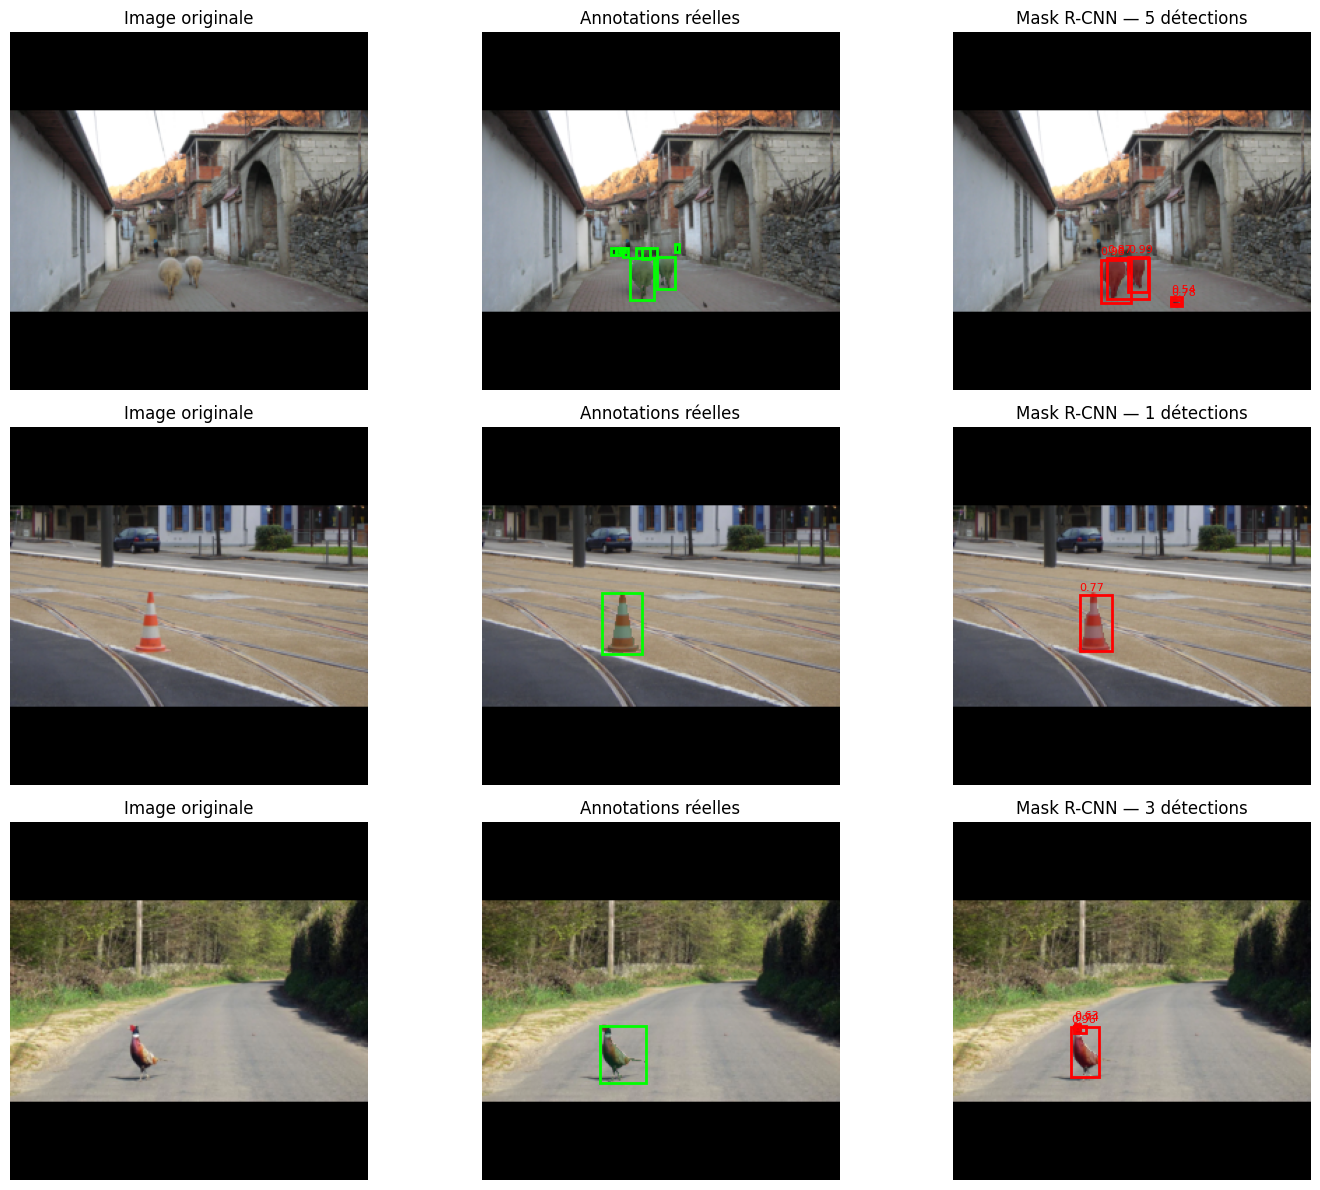

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Rectangle

model.eval()
test_dataset = test_loader.dataset

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

with torch.no_grad():
    for i in range(3):

        image, target = test_dataset[i]
        output = model([image.to(device)])[0]

        image_np = image.permute(1, 2, 0).cpu().numpy()

        # Image originale
        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title("Image originale")

        # Annotations réelles
        axes[i, 1].imshow(image_np)

        for box, mask in zip(
            target["boxes"], target["masks"]
        ):
            xmin, ymin, xmax, ymax = box.tolist()

            axes[i, 1].add_patch(
                Rectangle(
                    (xmin, ymin),
                    xmax - xmin,
                    ymax - ymin,
                    fill=False,
                    edgecolor="lime",
                    linewidth=2
                )
            )

            axes[i, 1].imshow(
                np.ma.masked_where(
                    mask.numpy() == 0,
                    mask.numpy()
                ),
                cmap="Greens",
                alpha=0.4,
                vmin=0,
                vmax=1
            )

        axes[i, 1].set_title("Annotations réelles")

        # Prédictions
        axes[i, 2].imshow(image_np)

        scores = output["scores"].cpu()
        selected = torch.where(scores >= 0.5)[0]

        for j in selected:

            box = output["boxes"][j].cpu().tolist()
            mask = (
                output["masks"][j, 0].cpu().numpy()
                >= 0.5
            )

            xmin, ymin, xmax, ymax = box

            axes[i, 2].add_patch(
                Rectangle(
                    (xmin, ymin),
                    xmax - xmin,
                    ymax - ymin,
                    fill=False,
                    edgecolor="red",
                    linewidth=2
                )
            )

            axes[i, 2].imshow(
                np.ma.masked_where(~mask, mask),
                cmap="Reds",
                alpha=0.4,
                vmin=0,
                vmax=1
            )

            axes[i, 2].text(
                xmin,
                max(0, ymin - 3),
                f"{scores[j]:.2f}",
                color="red",
                fontsize=8
            )

        axes[i, 2].set_title(
            f"Mask R-CNN — {len(selected)} détections"
        )

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()

## 9. Conclusion — Mask R-CNN

Nous avons entraîné Mask R-CNN avec un backbone ResNet50-FPN préentraîné sur COCO pour détecter et segmenter individuellement les obstacles routiers.

### Entraînement

- 33 images d'entraînement et 5 images de validation.
- Early Stopping à l'époque 15.
- Meilleur modèle à l'époque 10.
- Meilleure Validation Loss : 0.8149.

### Résultats sur les 8 images de test

| Métrique | Résultat |
|---|---|
| Mask IoU (instances correctement associées) | 0.7378 |
| Precision | 0.3714 |
| Recall | 0.5417 |
| AP@50 | 0.5402 |
| Vrais positifs | 13 |
| Faux positifs | 22 |
| Faux négatifs | 11 |

### Analyse

Mask R-CNN permet de détecter plusieurs obstacles individuellement et de produire leurs bounding boxes ainsi que leurs masques.

Les prédictions montrent une localisation correcte de certains objets, notamment les animaux et les cônes de signalisation.

Cependant, le modèle génère encore de nombreux faux positifs et manque certains obstacles.

Le petit nombre d'images annotées limite les performances et la généralisation.

### Conclusion

Mask R-CNN répond à notre objectif de segmentation des instances (DSO2), mais nécessite des améliorations pour fiabiliser la détection des obstacles.

Ses métriques par instance ne sont pas directement comparables aux métriques par pixel de nos modèles de segmentation sémantique.